<a href="https://www.kaggle.com/code/parsalatifi/tutorial-california-housing-clustering-dbscan?scriptVersionId=357001561" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# all libraries we need 
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
plt.style.use('dark_background')

import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook"

from sklearn.preprocessing import StandardScaler


#modeling libraries
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score as ss
import itertools 

In [2]:
data=pd.read_csv("/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv")
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
cols=['housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']

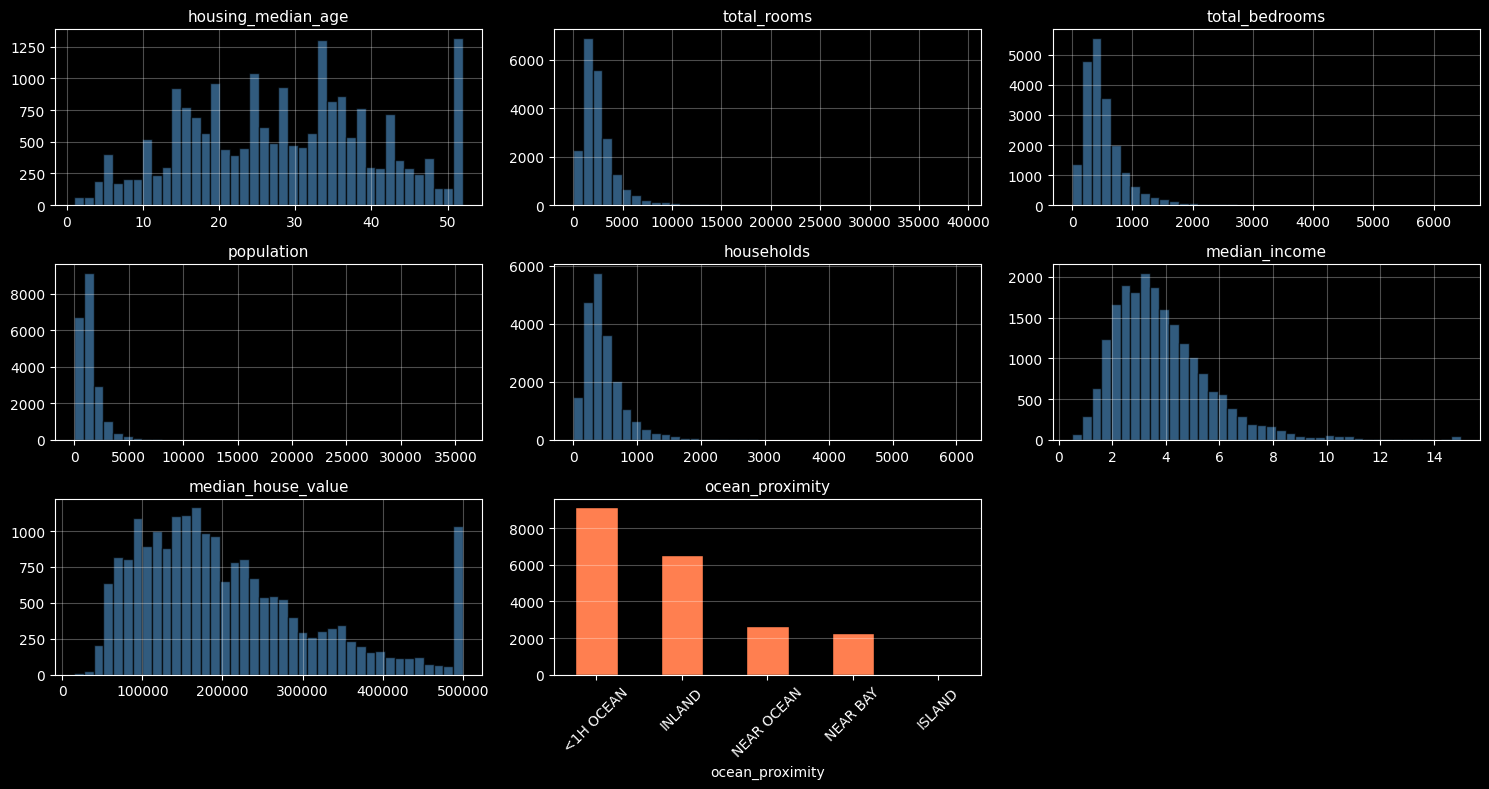

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cols):
  axes[i].hist(data[col].dropna(), bins=40, color='steelblue', edgecolor='black', alpha=0.7)
  axes[i].set_title(col, fontsize=11)
  axes[i].grid(alpha=0.3)


data['ocean_proximity'].value_counts().plot(kind='bar', ax=axes[7], color='coral', edgecolor='black')
axes[7].set_title('ocean_proximity', fontsize=11)
axes[7].tick_params(axis='x', rotation=45)
axes[7].grid(alpha=0.3, axis='y')

for j in range(8, len(axes)):
  axes[j].axis('off')

plt.tight_layout()
plt.show()

### Exploratory Data Analysis Report: California Housing Dataset

#### 1. Overview

* **Right-Skewed Features:** Features like `total_rooms`, `total_bedrooms`, `population`, `households`, and `median_income` are skewed to the right with long tails.


* **Capped Features:** Both `housing_median_age` (capped at 52) and `median_house_value` (capped at $500,000) have artificial maximum limits that create sharp spikes.


* **Categorical Feature:** `ocean_proximity` is imbalanced, dominated by `<1H OCEAN` and `INLAND`, with almost no `ISLAND` values.



---

#### 2. Feature Breakdown

* **`housing_median_age`:** Multimodal distribution with an artificial peak at 52 years.


* **`total_rooms`:** Highly right-skewed distribution with values stretching beyond 10,000 rooms.


* **`total_bedrooms`:** Right-skewed distribution with extreme outliers exceeding 2,000 bedrooms.


* **`population`:** Heavy right-skewed distribution with large outliers above 5,000 residents.


* **`households`:** Right-skewed distribution with high values extending past 1,500 households.


* **`median_income`:** Moderately right-skewed distribution centered around 2–5 with a tail extending up to 15.


* **`median_house_value`:** Target variable showing a right-skewed pattern with a significant capping line at $500,000.


* **`ocean_proximity`:** Categorical distribution where `<1H OCEAN` and `INLAND` represent the majority of samples, while `ISLAND` has near-zero representation.

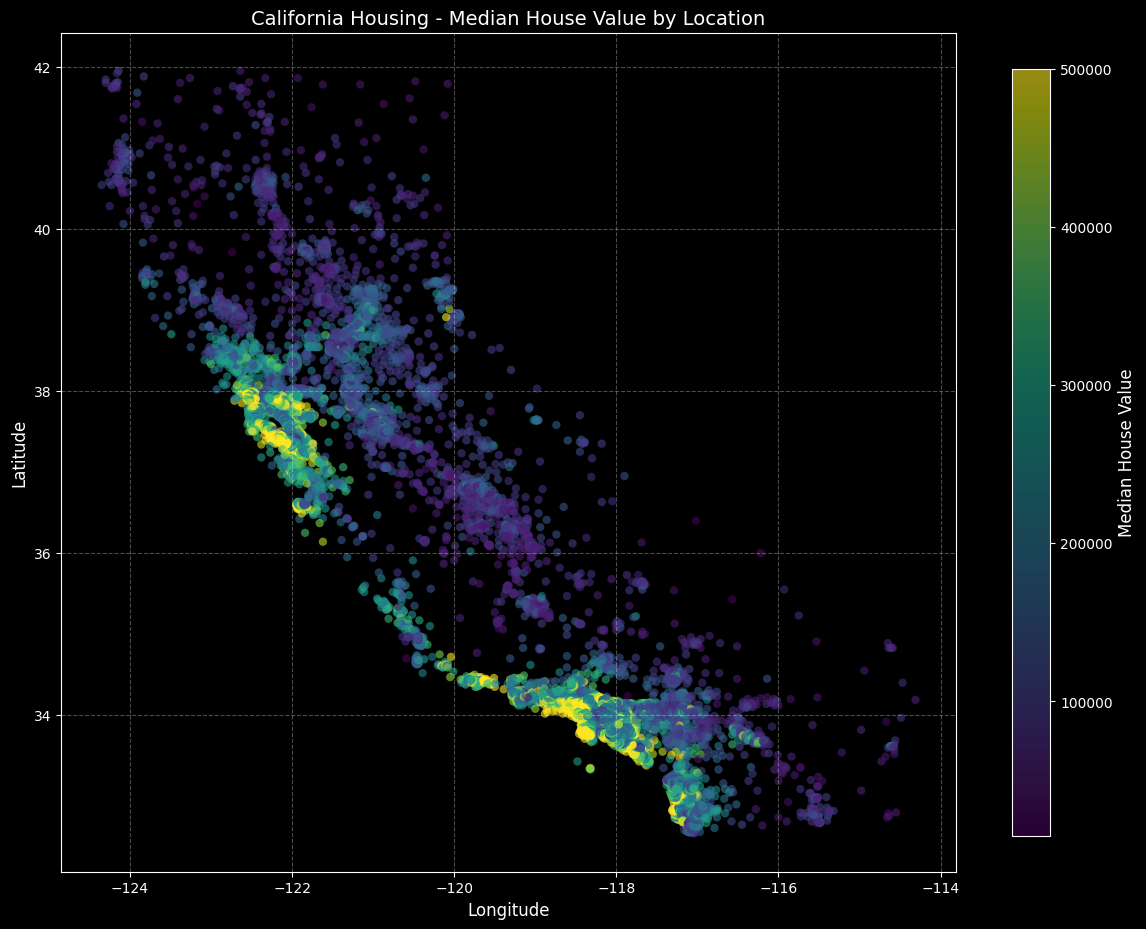

In [5]:
fig, ax = plt.subplots(figsize=(12, 10))

scatter = ax.scatter(
    data['longitude'],
    data['latitude'],
    c=data['median_house_value'],
    cmap='viridis',
    alpha=0.6,
    edgecolors='none'
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.8)
cbar.set_label('Median House Value', fontsize=12)

ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.set_title('California Housing - Median House Value by Location', fontsize=14)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

In [6]:
# cleaning the data part1
print("Number of missing values in each column:")
print(data.isnull().sum())
data.dropna(inplace=True)
print("\nNumber of missing values after dropping rows with missing values:")
print(data.isnull().sum())
print("\nNumber of duplicate rows:")
print(data.duplicated().sum())
data.drop_duplicates(inplace=True)
print("\nNumber of duplicate rows after dropping duplicates:")
print(data.duplicated().sum())


Number of missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Number of missing values after dropping rows with missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

Number of duplicate rows:
0

Number of duplicate rows after dropping duplicates:
0


In [7]:
# cleaning the data part2
# Removing artificial outliers based on domain knowledge and visual inspection
# For example, we can remove rows where 'median_house_value' is greater than $500,000
data = data[data['median_house_value'] <= 500000]
data = data[data['median_income'] <= 15]
data= data[data['housing_median_age'] <= 50]  

In [8]:
# one-hot encoding for categorical variable 'ocean_proximity'
data = pd.get_dummies(data, columns=['ocean_proximity'])
data = data.drop(columns=['ocean_proximity_ISLAND'])  # Drop one category to avoid multicollinearity
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,True,False
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,False,False,True,False
15,-122.26,37.85,50.0,1120.0,283.0,697.0,264.0,2.1250,140000.0,False,False,True,False
18,-122.26,37.84,50.0,2239.0,455.0,990.0,419.0,1.9911,158700.0,False,False,True,False


In [9]:
s1=StandardScaler()
data_scaled = s1.fit_transform(data[['longitude','latitude','housing_median_age',
                                      'total_rooms', 'total_bedrooms', 'population', 
                                      'households', 'median_income', 'median_house_value']])

    

## Model

In [10]:
epsilons = np.linspace(0.01, 1, 15)
min_samples_list = np.arange(2, 20, step=3)
combinations = list(itertools.product(epsilons, min_samples_list))
combinations[0:5]

[(np.float64(0.01), np.int64(2)),
 (np.float64(0.01), np.int64(5)),
 (np.float64(0.01), np.int64(8)),
 (np.float64(0.01), np.int64(11)),
 (np.float64(0.01), np.int64(14))]

In [11]:
N = len(combinations)



def get_scores_and_labels(combinations, X):
    # Store silhouette score for each combination
    scores = []
    
    # Store labels (or 'bad') for each combination
    all_labels_list = []

    for i, (eps, num_samples) in enumerate(combinations):
        # Fit DBSCAN with current hyperparameters
        dbscan_cluster_model = DBSCAN(eps=eps, min_samples=num_samples).fit(X)
        
        # Extract cluster labels assigned to each sample
        labels = dbscan_cluster_model.labels_
        
        # Get unique labels (including -1 for noise if present)
        labels_set = set(labels)
        
        # Count the number of clusters (excluding noise label -1)
        num_clusters = len(labels_set)
        if -1 in labels_set:
            num_clusters -= 1

        # Skip combinations that produce too few or too many clusters
        if (num_clusters < 2) or (num_clusters > 50):
            scores.append(-10)
            all_labels_list.append('bad')
            c = (eps, num_samples)
            print(f"Combination {c} on iteration {i+1} of {N} has {num_clusters} clusters. Moving on")
            continue

        # Evaluate clustering quality using silhouette score
        scores.append(ss(X, labels))
        all_labels_list.append(labels)
        print(f"Index: {i}, Score: {scores[-1]}, Labels: {all_labels_list[-1]}, NumClusters: {num_clusters}")

    # Find the combination with the highest silhouette score
    best_index = np.argmax(scores)
    best_parameters = combinations[best_index]
    best_labels = all_labels_list[best_index]
    best_score = scores[best_index]

    # Return the best parameters, labels, and score
    return {'best_epsilon': best_parameters[0],
            'best_min_samples': best_parameters[1],
            'best_labels': best_labels,
            'best_score': best_score}

# Run the function with the defined combinations and the longitude/latitude data
best_dict = get_scores_and_labels(combinations, data_scaled) 

Combination (np.float64(0.01), np.int64(2)) on iteration 1 of 90 has 0 clusters. Moving on
Combination (np.float64(0.01), np.int64(5)) on iteration 2 of 90 has 0 clusters. Moving on
Combination (np.float64(0.01), np.int64(8)) on iteration 3 of 90 has 0 clusters. Moving on
Combination (np.float64(0.01), np.int64(11)) on iteration 4 of 90 has 0 clusters. Moving on
Combination (np.float64(0.01), np.int64(14)) on iteration 5 of 90 has 0 clusters. Moving on
Combination (np.float64(0.01), np.int64(17)) on iteration 6 of 90 has 0 clusters. Moving on
Index: 6, Score: -0.2922023653243196, Labels: [-1 -1 -1 ... -1 -1 -1], NumClusters: 6
Combination (np.float64(0.08071428571428571), np.int64(5)) on iteration 8 of 90 has 0 clusters. Moving on
Combination (np.float64(0.08071428571428571), np.int64(8)) on iteration 9 of 90 has 0 clusters. Moving on
Combination (np.float64(0.08071428571428571), np.int64(11)) on iteration 10 of 90 has 0 clusters. Moving on
Combination (np.float64(0.08071428571428571),

Best Epsilon: 1.0, Best Min Samples: 5, Best Score: 0.49395508377253144


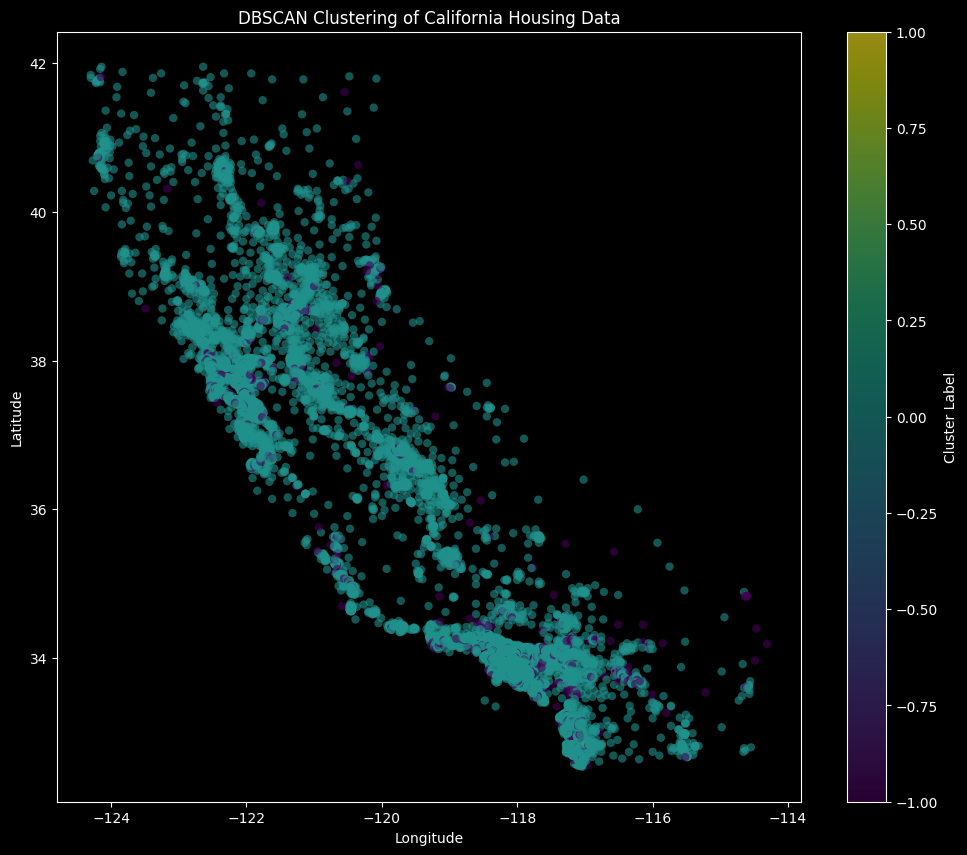

In [12]:
print(f"Best Epsilon: {best_dict['best_epsilon']}, Best Min Samples: {best_dict['best_min_samples']}, Best Score: {best_dict['best_score']}")
data['cluster'] = best_dict['best_labels']
fig=plt.figure(figsize=(12, 10))
plt.scatter(data['longitude'], data['latitude'], c=data['cluster'], cmap='viridis', alpha=0.6, edgecolors='none')
plt.colorbar(label='Cluster Label')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('DBSCAN Clustering of California Housing Data')
plt.show()


In [13]:
'''
find best combination of eps and min_samples for DBSCAN clustering on
 the California housing dataset. The function get_scores_and_labels evaluates different combinations 
 of hyperparameters and returns the best combination based on silhouette score. 
 The final clustering results are visualized on a scatter plot of longitude vs latitude, colored by cluster labels.
'''
# note: it's a tutorial, so the code is not optimized for performance. It is designed to be clear and educational,
#  demonstrating how to use DBSCAN clustering and evaluate its performance using silhouette scores.

'\nfind best combination of eps and min_samples for DBSCAN clustering on\n the California housing dataset. The function get_scores_and_labels evaluates different combinations \n of hyperparameters and returns the best combination based on silhouette score. \n The final clustering results are visualized on a scatter plot of longitude vs latitude, colored by cluster labels.\n'